In [2]:
# Load Twitter dataset and basic info
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)

DATA_PATH = 'twitter_training.csv'
df_raw = pd.read_csv(DATA_PATH, header=None, names=['tweet_id','topic','sentiment','text'], encoding='utf-8')
# Clean
df_raw['text'] = df_raw['text'].astype(str).str.strip()
df_raw['topic'] = df_raw['topic'].astype(str).str.strip()
df_raw['sentiment'] = df_raw['sentiment'].astype(str).str.strip()

# Drop empties/dupes
mask_empty = df_raw['text'].eq('') | df_raw['sentiment'].eq('')
df = df_raw.loc[~mask_empty].dropna(subset=['text','sentiment']).drop_duplicates()
print('Shape:', df.shape)
df.head()


Shape: (71443, 4)


,tweet_id,topic,sentiment,text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


Missing per column (%):


tweet_id     0.0
topic        0.0
sentiment    0.0
text         0.0
dtype: float64

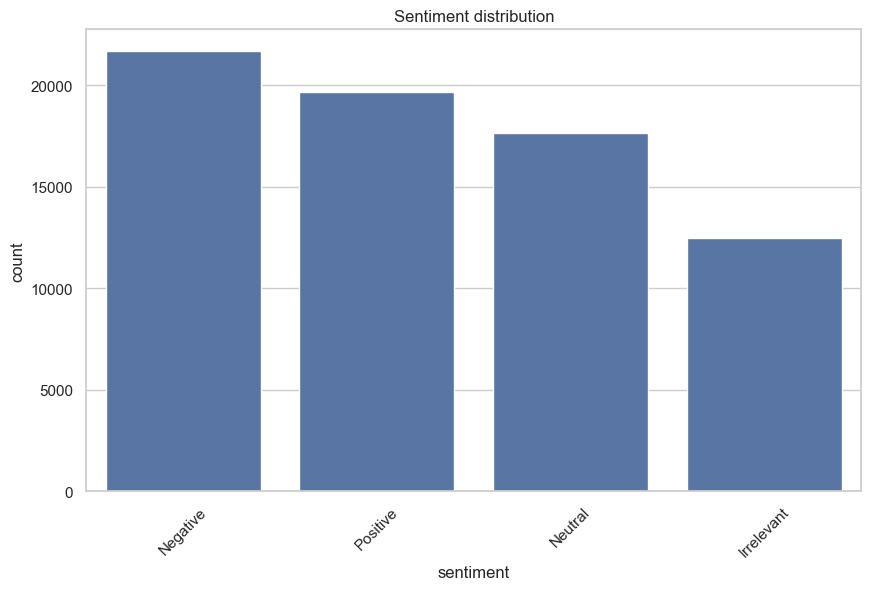

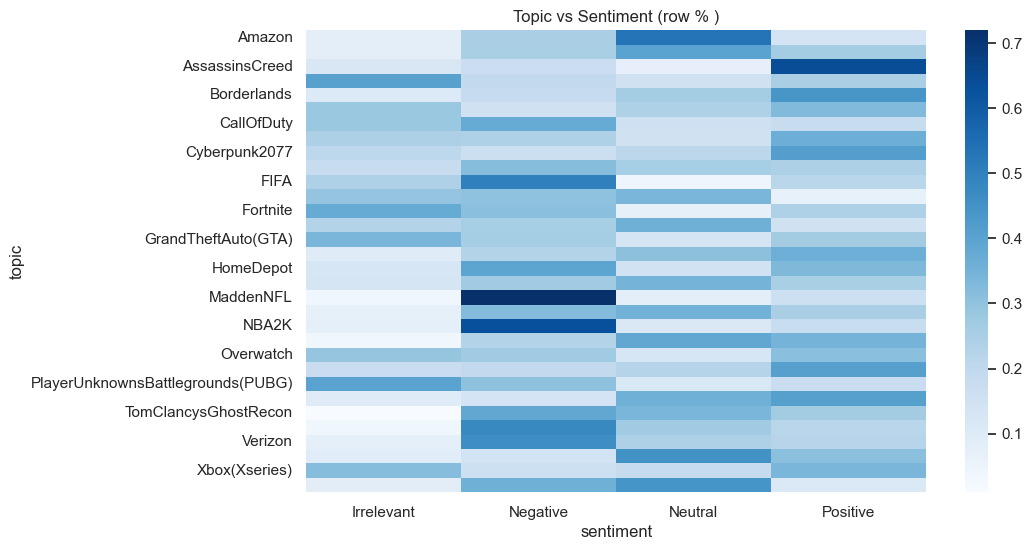

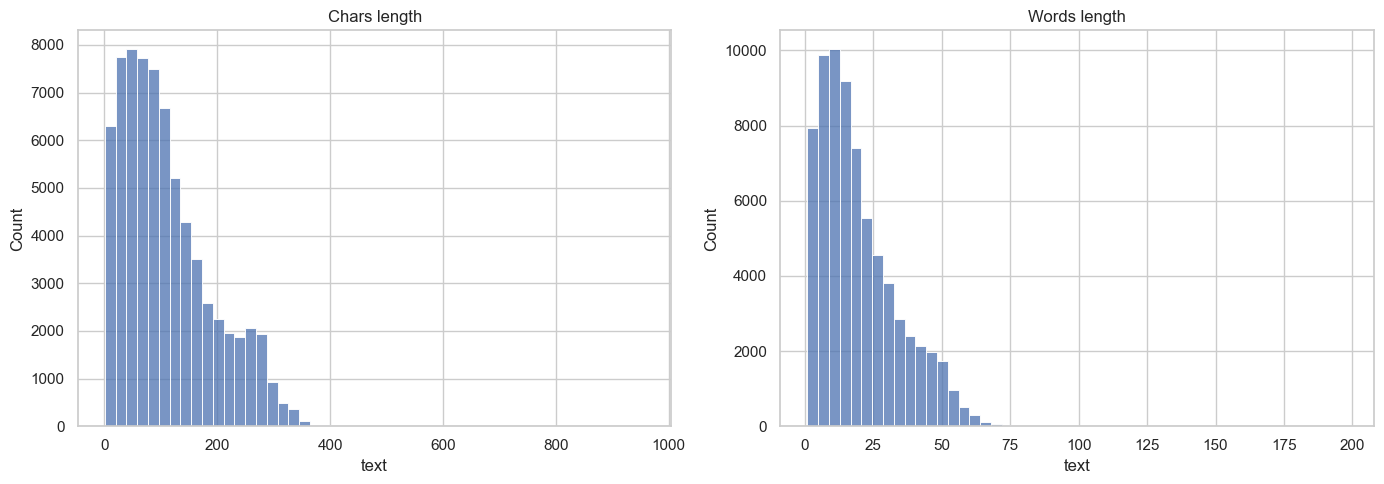

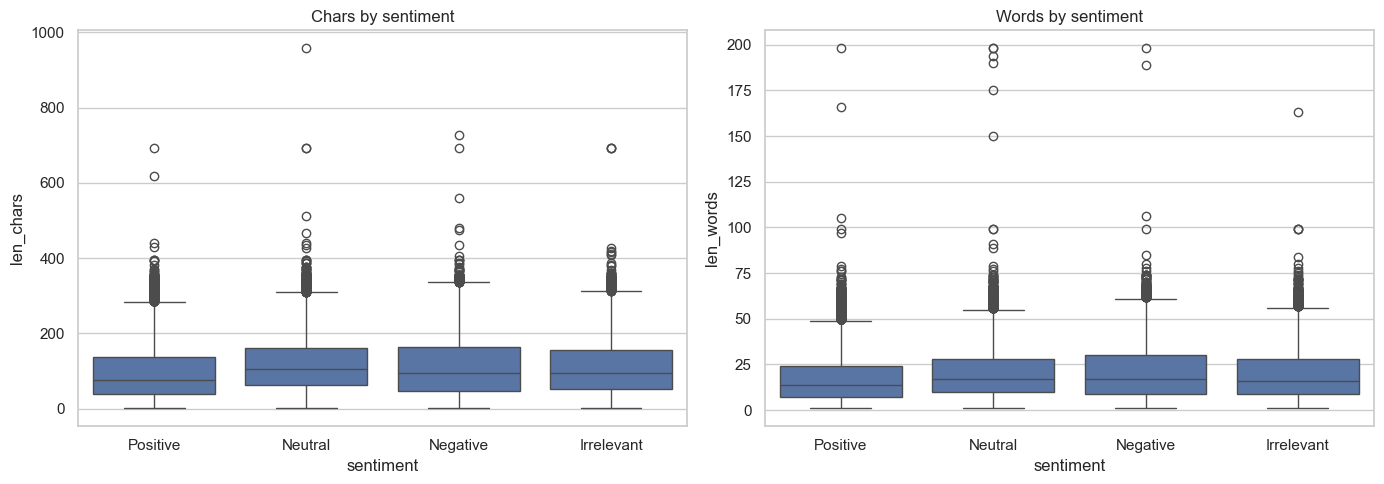

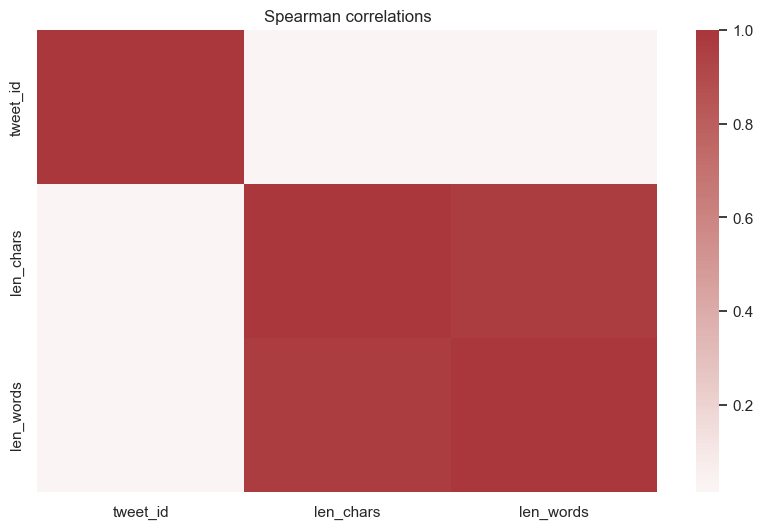

In [3]:
# EDA: missingness, target distribution, text lengths
print('Missing per column (%):')
display((df.isna().mean() * 100).round(2))

# Sentiment distribution
sns.countplot(data=df, x='sentiment', order=df['sentiment'].value_counts().index)
plt.title('Sentiment distribution'); plt.xticks(rotation=45); plt.show()

# Topic vs sentiment heatmap
cts = pd.crosstab(df['topic'], df['sentiment'])
cts_pct = cts.div(cts.sum(1), 0)
sns.heatmap(cts_pct, cmap='Blues', cbar=True)
plt.title('Topic vs Sentiment (row % )'); plt.ylabel('topic'); plt.xlabel('sentiment'); plt.show()

# Text length features for EDA
text_len_chars = df['text'].str.len()
text_len_words = df['text'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(text_len_chars, bins=50, ax=axes[0]); axes[0].set_title('Chars length')
sns.histplot(text_len_words, bins=50, ax=axes[1]); axes[1].set_title('Words length')
plt.tight_layout(); plt.show()

# Boxplots by sentiment
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=df['sentiment'], y=text_len_chars, ax=axes[0])
axes[0].set_title('Chars by sentiment'); axes[0].set_xlabel('sentiment'); axes[0].set_ylabel('len_chars')
sns.boxplot(x=df['sentiment'], y=text_len_words, ax=axes[1])
axes[1].set_title('Words by sentiment'); axes[1].set_xlabel('sentiment'); axes[1].set_ylabel('len_words')
plt.tight_layout(); plt.show()

# Numeric correlations (tweet_id and derived lengths)
num_df = pd.DataFrame({'tweet_id': df['tweet_id'], 'len_chars': text_len_chars, 'len_words': text_len_words})
sns.heatmap(num_df.corr(method='spearman'), annot=False, cmap='vlag', center=0)
plt.title('Spearman correlations'); plt.show()


In [4]:
# Preprocessing: encoders, scalers, TF-IDF, and feature union
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer

# Columns
col_id, col_topic, col_label, col_text = 'tweet_id','topic','sentiment','text'

# Derived numeric features
df['len_chars'] = df['text'].str.len()
df['len_words'] = df['text'].str.split().str.len()
df['num_hashtags'] = df['text'].str.count(r'#')
df['num_mentions'] = df['text'].str.count(r'@')
df['num_urls'] = df['text'].str.count(r'https?://|www\.')

numeric_features = ['tweet_id','len_chars','len_words','num_hashtags','num_mentions','num_urls']
categorical_features = ['topic']
text_feature = 'text'

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler(with_mean=False))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

text_transformer = TfidfVectorizer(ngram_range=(1,2), min_df=5, max_features=20000)

preprocess = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
        ('txt', text_transformer, text_feature)
    ],
    sparse_threshold=0.3
)

# Label encoding for y
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(df[col_label].astype(str))
X = df[[col_id, col_topic, col_text] + ['len_chars','len_words','num_hashtags','num_mentions','num_urls']]
label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
label_mapping


{'Irrelevant': np.int64(0),
 'Negative': np.int64(1),
 'Neutral': np.int64(2),
 'Positive': np.int64(3)}

In [5]:
# Split: train/val/test (80/10/10) stratified by sentiment
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)


Train: (57154, 8) Val: (7144, 8) Test: (7145, 8)


In [6]:

# Define model factory with unified pipelines
from sklearn.pipeline import Pipeline
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB

# Optional: only if using XGBoost
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False


models = []

# Logistic Regression (multinomial)
models.append(('logreg', Pipeline([
    ('preprocess', preprocess),
    ('clf', LogisticRegression(max_iter=2000, solver='saga', C=1.0, n_jobs=-1))
])))

# Linear SVM with probability via calibration
models.append(('linear_svc', Pipeline([
    ('preprocess', preprocess),
    ('clf', CalibratedClassifierCV(LinearSVC(C=1.0), method='sigmoid', cv=3))
])))

# Random Forest
models.append(('rf', Pipeline([
    ('preprocess', preprocess),
    ('clf', RandomForestClassifier(n_estimators=300, max_depth=None, n_jobs=-1, random_state=42))
])))

# MultinomialNB (works with TF-IDF)
models.append(('mnb', Pipeline([
    ('preprocess', preprocess),
    ('clf', MultinomialNB(alpha=1.0))
])))

# ComplementNB
models.append(('cnb', Pipeline([
    ('preprocess', preprocess),
    ('clf', ComplementNB(alpha=1.0))
])))

# XGBoost (if available)
if HAS_XGB:
    models.append(('xgb', Pipeline([
        ('preprocess', preprocess),
        ('clf', XGBClassifier(
            n_estimators=400,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.9,
            colsample_bytree=0.9,
            objective='multi:softprob',
            eval_metric='mlogloss',
            tree_method='hist',
            random_state=42,
            n_jobs=-1
        ))
    ])))

len(models), [name for name,_ in models]


(5, ['logreg', 'linear_svc', 'rf', 'mnb', 'cnb'])

In [ ]:
# Train and evaluate on validation set
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
from sklearn.preprocessing import label_binarize
import numpy as np

results = []
val_probs_store = {}

classes_ = np.unique(y_train)
for name, pipe in models:
    print(f'Fitting: {name}')
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_val)

    # Try to get probabilities or decision scores
    y_score = None
    if hasattr(pipe, 'predict_proba'):
        try:
            y_score = pipe.predict_proba(X_val)
        except Exception:
            y_score = None
    if y_score is None and hasattr(pipe, 'decision_function'):
        try:
            scores = pipe.decision_function(X_val)
            # Convert to probability-like via softmax for ROC-AUC macro
            if scores.ndim == 1:
                # binary-like; stack two columns
                scores = np.vstack([-scores, scores]).T
            exp_scores = np.exp(scores - scores.max(axis=1, keepdims=True))
            y_score = exp_scores / exp_scores.sum(axis=1, keepdims=True)
        except Exception:
            y_score = None

    acc = accuracy_score(y_val, y_pred)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(y_val, y_pred, average='weighted', zero_division=0)
    prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(y_val, y_pred, average='macro', zero_division=0)

    roc = np.nan
    if y_score is not None:
        try:
            y_val_bin = label_binarize(y_val, classes=np.unique(y))
            roc = roc_auc_score(y_val_bin, y_score, average='macro', multi_class='ovr')
        except Exception:
            roc = np.nan

    results.append({
        'model': name,
        'accuracy': acc,
        'precision_weighted': prec_w,
        'recall_weighted': rec_w,
        'f1_weighted': f1_w,
        'precision_macro': prec_m,
        'recall_macro': rec_m,
        'f1_macro': f1_m,
        'roc_auc_macro': roc
    })

    if y_score is not None:
        val_probs_store[name] = y_score

results_df = pd.DataFrame(results).sort_values(['f1_macro','roc_auc_macro','accuracy'], ascending=False)
results_df


Fitting: logreg


In [ ]:
# Select top-2 by macro F1, refit on train+val, evaluate on test; plot ROC
from sklearn.metrics import ConfusionMatrixDisplay

# Pick top 2
top2 = results_df.head(2)['model'].tolist()
print('Top 2 models:', top2)

final_rows = []
final_curves = {}

X_trval = pd.concat([X_train, X_val], axis=0)
y_trval = np.concatenate([y_train, y_val])

lookup = {name: pipe for name, pipe in models}
for name in top2:
    print('Refitting on train+val:', name)
    pipe = lookup[name]
    pipe.fit(X_trval, y_trval)
    y_pred = pipe.predict(X_test)

    # probs or decision scores
    y_score = None
    if hasattr(pipe, 'predict_proba'):
        try:
            y_score = pipe.predict_proba(X_test)
        except Exception:
            y_score = None
    if y_score is None and hasattr(pipe, 'decision_function'):
        try:
            scores = pipe.decision_function(X_test)
            if scores.ndim == 1:
                scores = np.vstack([-scores, scores]).T
            exp_scores = np.exp(scores - scores.max(axis=1, keepdims=True))
            y_score = exp_scores / exp_scores.sum(axis=1, keepdims=True)
        except Exception:
            y_score = None

    acc = accuracy_score(y_test, y_pred)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)
    prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)

    roc = np.nan
    if y_score is not None:
        try:
            y_test_bin = label_binarize(y_test, classes=np.unique(y))
            roc = roc_auc_score(y_test_bin, y_score, average='macro', multi_class='ovr')
        except Exception:
            roc = np.nan

    final_rows.append({'model': name, 'set': 'test',
                       'accuracy': acc,
                       'precision_weighted': prec_w,
                       'recall_weighted': rec_w,
                       'f1_weighted': f1_w,
                       'precision_macro': prec_m,
                       'recall_macro': rec_m,
                       'f1_macro': f1_m,
                       'roc_auc_macro': roc})

    # Confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=le.classes_)
    disp.plot(cmap='Blues', xticks_rotation=45)
    plt.title(f'Confusion Matrix - {name} (test)'); plt.show()

    # ROC curves (macro)
    if y_score is not None:
        from sklearn.metrics import RocCurveDisplay
        try:
            y_test_bin = label_binarize(y_test, classes=np.unique(y))
            for i, cls in enumerate(le.classes_):
                RocCurveDisplay.from_predictions(y_test_bin[:, i], y_score[:, i], name=f'{name} - {cls}')
            plt.title(f'ROC Curves (One-vs-Rest) - {name}'); plt.show()
        except Exception:
            pass

final_df = pd.DataFrame(final_rows)
final_df


In [ ]:
# Model comparison table: validation (all models) + test (finalists)
from IPython.display import display

summary = results_df.copy()
summary['set'] = 'validation'

final_summary = pd.concat([summary, final_df], ignore_index=True)
cols = ['model','set','accuracy','precision_macro','recall_macro','f1_macro','roc_auc_macro','precision_weighted','recall_weighted','f1_weighted']
final_summary = final_summary[cols].sort_values(['set','f1_macro','roc_auc_macro','accuracy'], ascending=[True, False, False, False])

display(final_summary)

print('\nLabel mapping (target -> id):', label_mapping)

